In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot-only notebook: the numbers are produced by `python postprocess.py` (-> ./data/*.csv)
os.makedirs('../plots', exist_ok=True)

In [2]:
df = pd.read_csv('data/ambguity_exp.csv')

In [3]:
indices = [0, 5, 100, 200, 450]

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MultipleLocator
from matplotlib.lines import Line2D

def plot_frequency_rate(trace_nums, accuracies, labels,
                        xlabel='offset',
                        ylabel='Collision Rate',
                        title='',
                        legend_title = '',
                        save_name = 'ambguity_rate',
                        figsize=(13, 8),
                        fontsize=40): 
    """
    Plot and show two legends:
      - Model origin (proxy): Extracted surrogate models (SCA) and CIFAR baseline
      - Baseline: numeric dashed line label
    """
    sns.set(style="whitegrid")
    fig, ax = plt.subplots(figsize=figsize)
    marker_cycle = ["o", "s", "^", "D", "v", "P", "X", "*", "<", ">", "h", "H", "p", "8", "+", "x"]
    # Plot each series
    line_objs = []
    for i, (acc, lab) in enumerate(zip(accuracies, labels)):
        line, = ax.plot(trace_nums, acc, marker=marker_cycle[i], linestyle='-', 
                        linewidth=1.5, markersize=13, 
                        label=lab)
        line_objs.append(line)



    # Labels, title, ticks
    ax.set_xlabel(xlabel, fontsize=fontsize)
    ax.set_ylabel(ylabel, fontsize=fontsize)
    ax.set_title(title, fontsize=fontsize)
    ax.tick_params(axis='y', labelsize=fontsize)
    ax.tick_params(axis='x', labelsize=fontsize)

    # Y limits/ticks
    ax.set_ylim(0, 1.05)
    #ax.yaxis.set_major_locator(MultipleLocator(0.1))
    ax.grid(True)

    # Legends
    fig.subplots_adjust(right=0.75)
    ax.legend(title=legend_title, fontsize=fontsize, title_fontsize=fontsize)

    plt.tight_layout()
    plt.show()
    fig.savefig(f"../plots/{save_name}.pdf",
            format="pdf",
            bbox_inches="tight",
            metadata={"Creator": "Matplotlib"})

In [5]:
# collision rate of the next 100 partial sums when conv4 weight `index` is nudged by +/- one float16 ulp
def rates(eps_sign):
    return [df[(df.eps_sign == eps_sign) & (df.weight_index == i)].sort_values('offset')['collision_rate'].to_numpy()
            for i in indices]

res_plus_eps = rates('plus')
res_minus_eps = rates('minus')

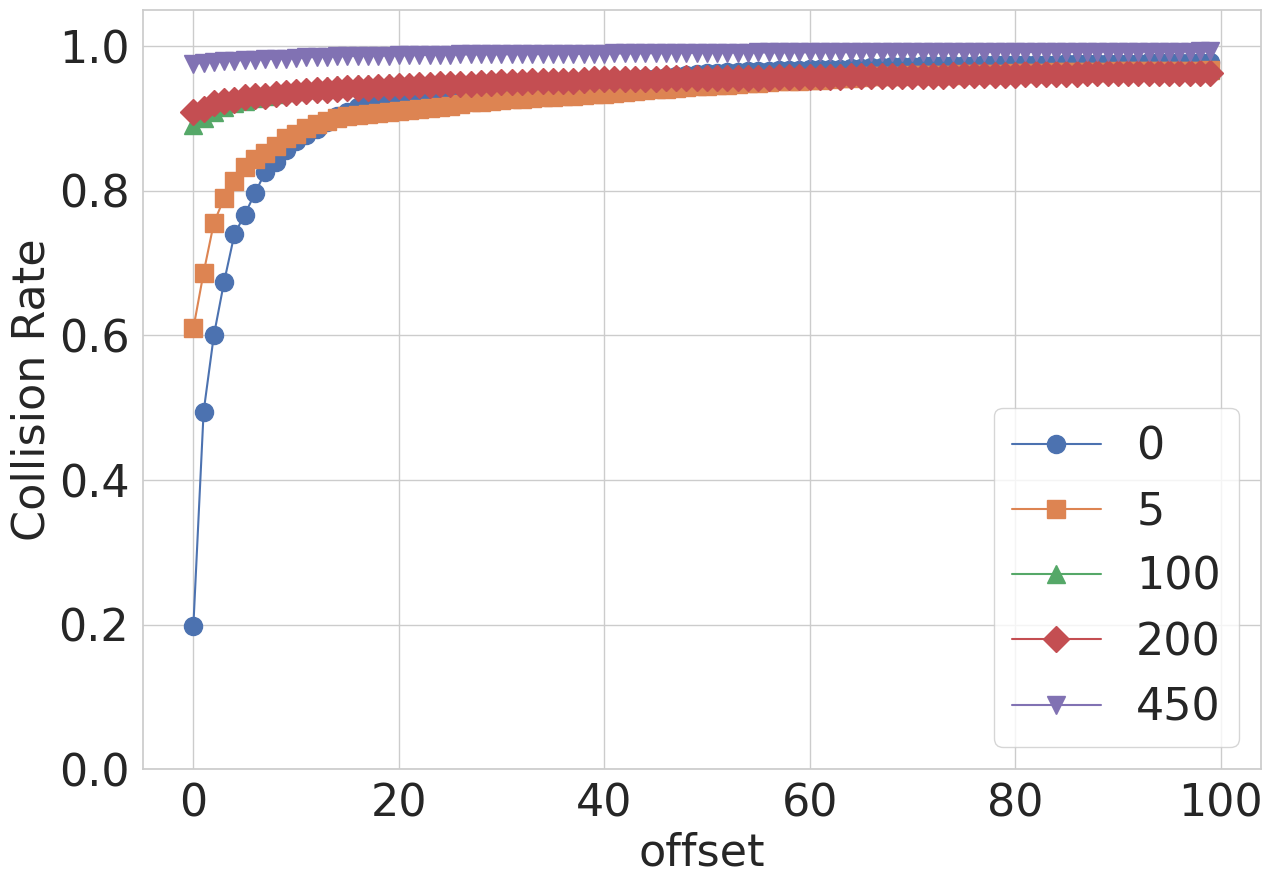

In [6]:
plot_frequency_rate([i for i in range(0, 100)], res_plus_eps, [str(i) for i in indices], fontsize=32, figsize=(13, 9))

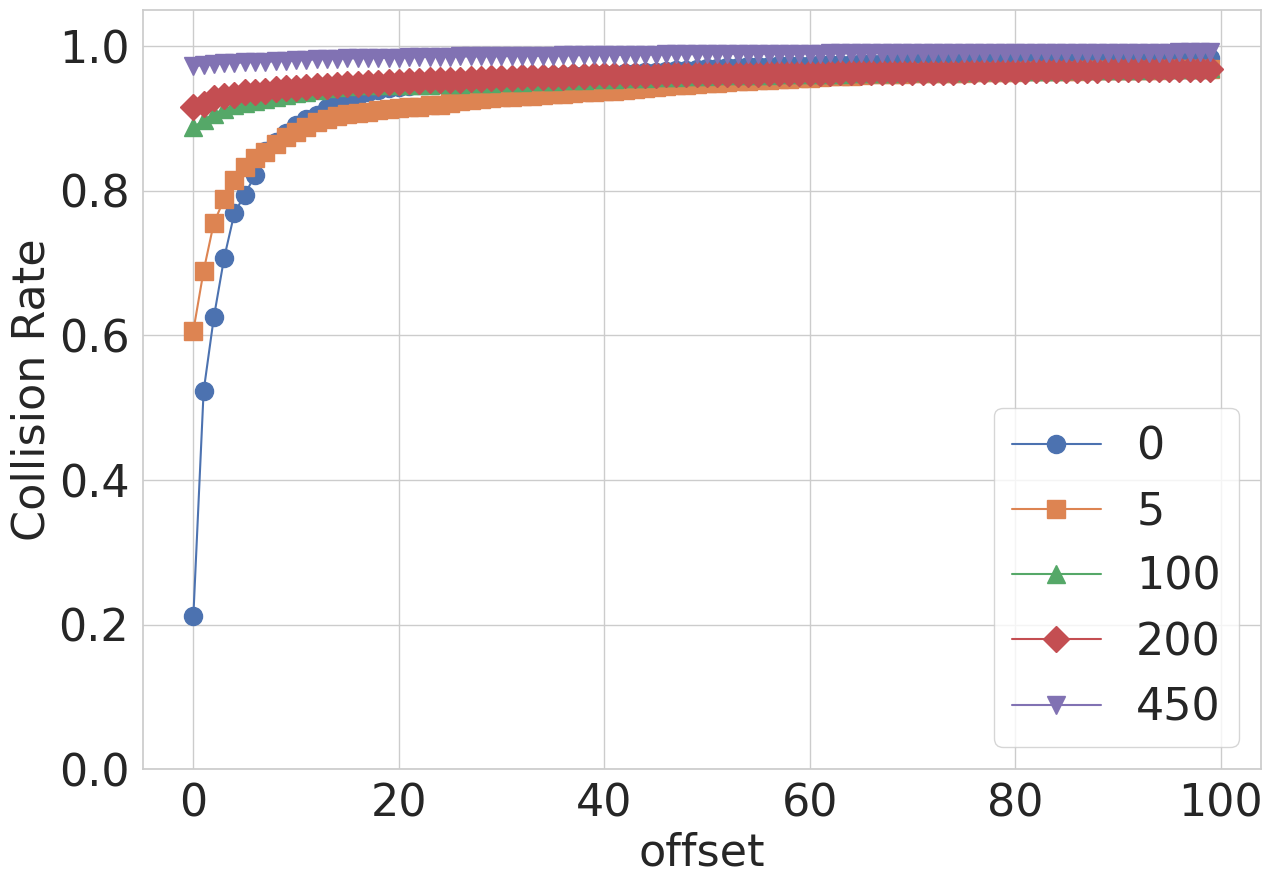

In [7]:
plot_frequency_rate([i for i in range(0, 100)], res_minus_eps, [str(i) for i in indices], fontsize=32, figsize=(13, 9), save_name = 'ambguity_rate_minus_eps')